# Assess: métricas, errores y herramienta

Laboratorio ESPE · Semilla 42 · Fuentes y límites documentados.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'data' / 'dataset.csv').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image
df = pd.read_csv(ROOT / 'data/dataset.csv', keep_default_na=False)
df['labels'] = df.labels.map(json.loads)
print('Raíz del laboratorio:', ROOT)


Raíz del laboratorio: D:\ESPE\36902-DESARROLLO SOFTWARE SEGURO\Pacial2\Trabajo


Objetivo: medir precisión, recall, F1 micro/macro, matrices binarias por etiqueta y errores, además de evaluar el flujo completo sobre dos fixtures ajenas al entrenamiento. Las fixtures se usaron para depurar el extractor; no son una evaluación ciega.

,precision,recall,f1-score,support
A01:2025,1.000000,1.0,1.000000,12.0
A02:2025,1.000000,1.0,1.000000,12.0
A04:2025,1.000000,1.0,1.000000,12.0
A05:2025,0.500000,1.0,0.666667,12.0
A07:2025,0.800000,1.0,0.888889,24.0
A08:2025,1.000000,1.0,1.000000,12.0
API10:2023,1.000000,1.0,1.000000,12.0
API2:2023,1.000000,1.0,1.000000,12.0
API7:2023,1.000000,1.0,1.000000,12.0
API8:2023,1.000000,1.0,1.000000,12.0


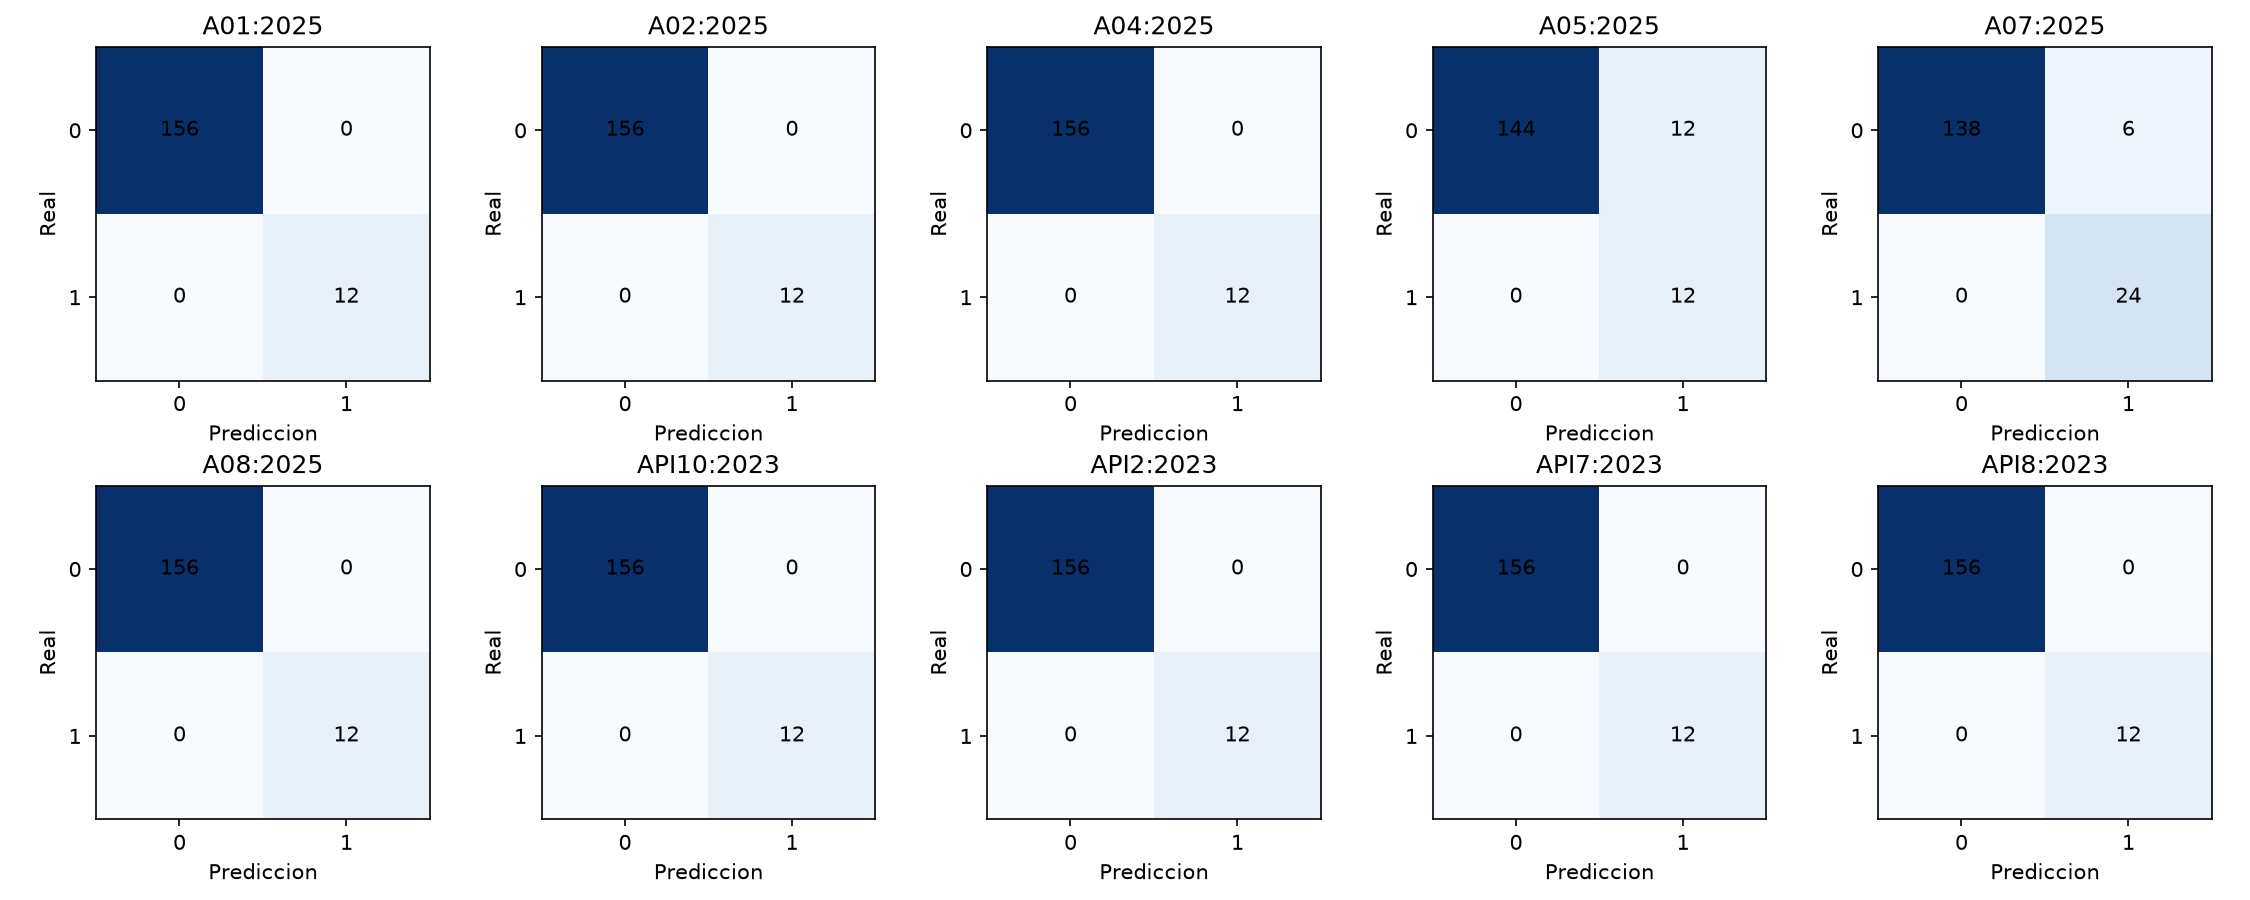

Registros de prueba con error: 18


,id,code,false_positive,false_negative,language,scenario
0,VM-0062,sql = 'UPDATE orders SET active=1 WHERE id=:va...,[A05:2025],[],Python,sql
1,VM-0064,sql = 'UPDATE accounts SET active=1 WHERE id=:...,[A05:2025],[],Python,sql
2,VM-0066,sql = 'UPDATE products SET active=1 WHERE id=:...,[A05:2025],[],Python,sql
3,VM-0068,sql = 'UPDATE invoices SET active=1 WHERE id=:...,[A05:2025],[],Python,sql
4,VM-0070,sql = 'UPDATE customers SET active=1 WHERE id=...,[A05:2025],[],Python,sql
5,VM-0072,sql = 'UPDATE payments SET active=1 WHERE id=:...,[A05:2025],[],Python,sql
6,VM-0566,repository.query('SELECT * FROM orders WHERE n...,[A05:2025],[],JavaScript,sql
7,VM-0568,repository.query('SELECT * FROM accounts WHERE...,[A05:2025],[],JavaScript,sql
8,VM-0570,repository.query('SELECT * FROM products WHERE...,[A05:2025],[],JavaScript,sql
9,VM-0572,repository.query('SELECT * FROM invoices WHERE...,[A05:2025],[],JavaScript,sql


In [2]:
metrics = json.loads((ROOT / 'output/evaluation/metrics.json').read_text())
selected = metrics['candidates'][metrics['selected']]
display(pd.DataFrame(selected['test']['per_category']).T)
display(Image(filename=str(ROOT / 'output/evaluation/confusion_matrices.png')))
errors = json.loads((ROOT / 'output/evaluation/errors.json').read_text())
print('Registros de prueba con error:', len(errors))
display(pd.DataFrame(errors).head(12))

In [3]:
from scripts.evaluate_projects import evaluate
projects = evaluate()
display(pd.DataFrame([{k:v for k,v in p.items() if k not in ['errors','unlabeled_config_findings','covered_categories']} for p in projects]))
for error in errors[:3]:
    print(error['id'], 'FP:', error['false_positive'], 'FN:', error['false_negative'])
    print(error['code'])

[
  {
    "project": "tienda-demo",
    "truth_files": 14,
    "tp": 7,
    "fp": 0,
    "fn": 0,
    "tn": 7,
    "precision": 1.0,
    "recall": 1.0,
    "f1": 1.0,
    "label_precision_micro": 1.0,
    "label_recall_micro": 1.0,
    "covered_categories": [
      "A01:2025",
      "A02:2025",
      "A04:2025",
      "A05:2025",
      "A07:2025",
      "A08:2025",
      "API10:2023",
      "API2:2023",
      "API7:2023",
      "API8:2023"
    ],
    "errors": [],
    "unlabeled_config_findings": []
  },
  {
    "project": "logistica-demo",
    "truth_files": 14,
    "tp": 7,
    "fp": 0,
    "fn": 0,
    "tn": 7,
    "precision": 1.0,
    "recall": 1.0,
    "f1": 1.0,
    "label_precision_micro": 1.0,
    "label_recall_micro": 1.0,
    "covered_categories": [
      "A01:2025",
      "A02:2025",
      "A04:2025",
      "A05:2025",
      "A07:2025",
      "A08:2025",
      "API10:2023",
      "API2:2023",
      "API7:2023",
      "API8:2023"
    ],
    "errors": [],
    "unlabeled_confi

,project,truth_files,tp,fp,fn,tn,precision,recall,f1,label_precision_micro,label_recall_micro
0,tienda-demo,14,7,0,0,7,1.0,1.0,1.0,1.0,1.0
1,logistica-demo,14,7,0,0,7,1.0,1.0,1.0,1.0,1.0


VM-0062 FP: ['A05:2025'] FN: []
sql = 'UPDATE orders SET active=1 WHERE id=:value'
connection.execute(sql, dict(value=user_input['name']))
VM-0064 FP: ['A05:2025'] FN: []
sql = 'UPDATE accounts SET active=1 WHERE id=:value'
connection.execute(sql, dict(value=user_input['id']))
VM-0066 FP: ['A05:2025'] FN: []
sql = 'UPDATE products SET active=1 WHERE id=:value'
connection.execute(sql, dict(value=user_input['value']))


Conclusión: el holdout por familia mide generalización dentro de siete patrones sintéticos. Los falsos positivos sobre fragmentos corregidos muestran que el modelo puede ignorar controles locales. La extracción y el umbral cambian los resultados de la CLI respecto a la clasificación aislada. El desempeño perfecto en unas pocas fixtures no implica desempeño perfecto en repositorios reales. Las categorías sin datos se declaran no evaluadas. Falta la evaluación del proyecto desconocido del docente y la validación manual/dinámica de explotabilidad.